In [18]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['figure.figsize'] = (10, 6)
import warnings
warnings.filterwarnings('ignore')

In [2]:
posts_df = pd.read_csv("../output/posts_feature_engineered.csv")

In [3]:
print(posts_df.shape)
posts_df.head()

(6912, 178)


,id,subreddit.name,topic,score,log_score,title_length,selftext_length,total_text_length,log_text_length,hour,...,topic_156,topic_157,topic_158,topic_159,topic_160,topic_161,topic_162,topic_163,topic_164,topic_165
0,t4euxw,datasets,21,1,0.693147,89,522,611,6.416732,18,...,False,False,False,False,False,False,False,False,False,False
1,t47wiw,datasets,4,2,1.098612,79,123,202,5.313206,13,...,False,False,False,False,False,False,False,False,False,False
2,t3uct4,datasets,79,1,0.693147,65,544,609,6.413459,0,...,False,False,False,False,False,False,False,False,False,False
3,t3sxj4,datasets,78,1,0.693147,64,6,70,4.262680,23,...,False,False,False,False,False,False,False,False,False,False
4,t3mxt5,datasets,80,1,0.693147,45,916,961,6.869014,18,...,False,False,False,False,False,False,False,False,False,False


In [4]:
segment_features = posts_df[[
    'log_score',
    'log_text_length',
    'hour',
    'is_weekend'
]]

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(segment_features)

#### K 후보 탐색 (Elbow + Silhouette)

In [19]:
ks = range(2, 9)
inertias = []
sil_scores = []

for k in ks:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = kmeans.fit_predict(X_scaled)
    inertias.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))


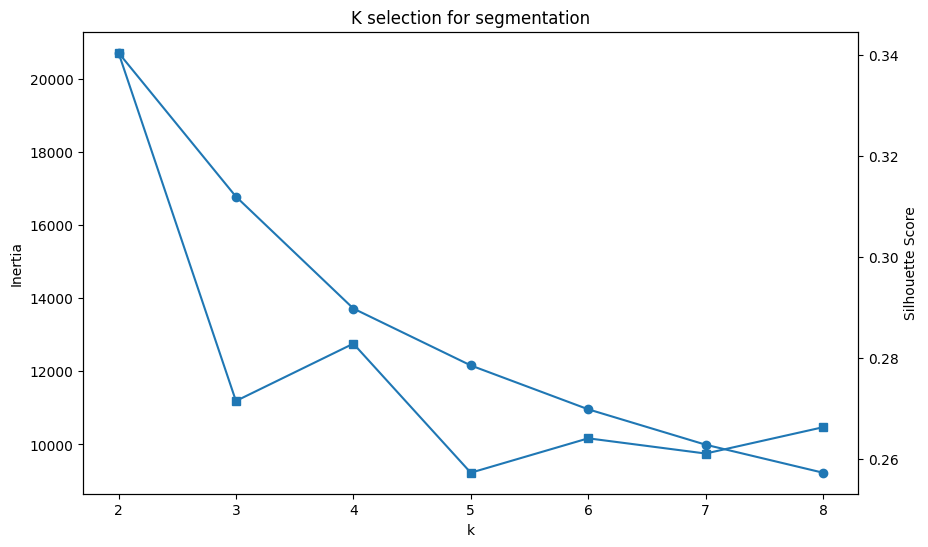

In [20]:
fig, ax1 = plt.subplots()
ax2 = ax1.twinx()

ax1.plot(ks, inertias, marker='o')
ax2.plot(ks, sil_scores, marker='s')

ax1.set_xlabel("k")
ax1.set_ylabel("Inertia")
ax2.set_ylabel("Silhouette Score")
plt.title("K selection for segmentation")
plt.show()

In [21]:
FINAL_K = 4

kmeans = KMeans(n_clusters=FINAL_K,
    random_state=42, n_init=20
)

posts_df['segment'] = kmeans.fit_predict(X_scaled)


In [22]:
segment_summary = posts_df.groupby('segment').agg({
    'score': 'mean',
    'title_length': 'mean',
    'selftext_length': 'mean',
    'total_text_length': 'mean',
    'hour': 'mean',
    'id': 'count'
}).rename(columns={'id': 'num_posts'}).reset_index()

segment_summary

,segment,score,title_length,selftext_length,total_text_length,hour,num_posts
0,0,3.016351,50.512077,311.231141,361.743218,17.396878,2691
1,1,27.528613,60.440349,985.475267,1045.915616,13.554801,1031
2,2,5.913621,51.317608,350.508970,401.826578,12.964784,1505
3,3,3.757864,51.197626,328.696736,379.894362,4.926409,1685


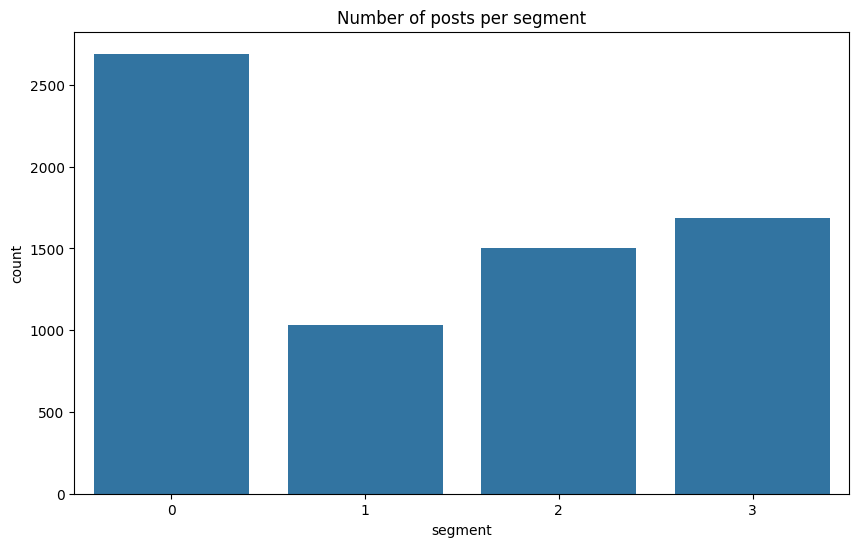

In [23]:
sns.countplot(x='segment', data=posts_df)
plt.title("Number of posts per segment")
plt.show()

In [24]:
segment_topic = (
    posts_df
    .groupby(['segment', 'topic'])
    .size()
    .reset_index(name='count')
)


In [25]:
segment_topic_ratio = (
    segment_topic
    .assign(
        ratio=lambda x: x['count'] /
        x.groupby('segment')['count'].transform('sum')
    )
)

segment_topic_ratio.head()

,segment,topic,count,ratio
0,0,0,47,0.017466
1,0,1,67,0.024898
2,0,2,78,0.028986
3,0,3,69,0.025641
4,0,4,49,0.018209


In [26]:
top_topics = (
    posts_df['topic']
    .value_counts()
    .head(10)
    .index
)

segment_topic_top = segment_topic_ratio[
    segment_topic_ratio['topic'].isin(top_topics)
]


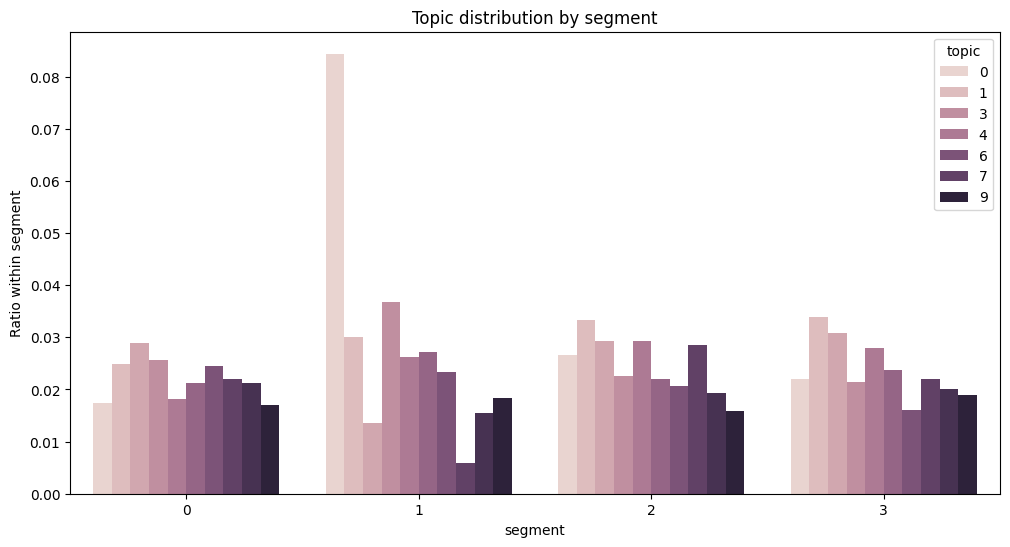

In [27]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=segment_topic_top,
    x='segment',
    y='ratio',
    hue='topic'
)
plt.title("Topic distribution by segment")
plt.ylabel("Ratio within segment")
plt.show()

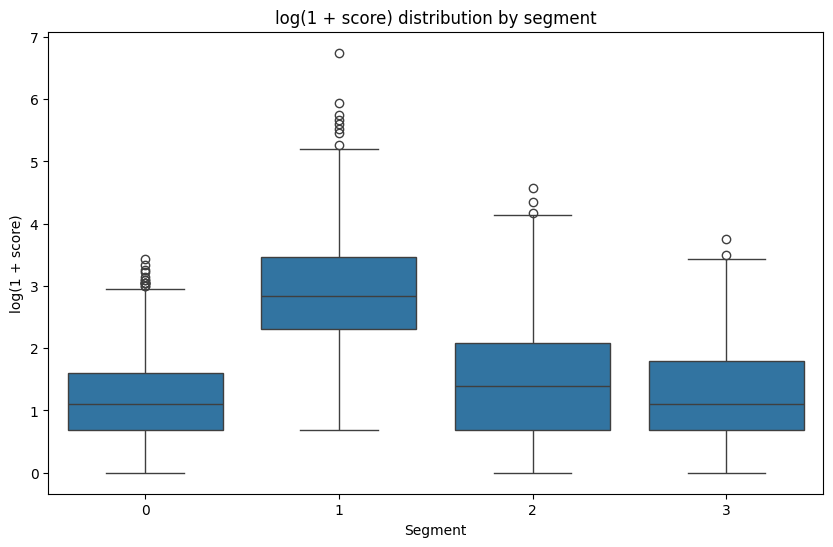

In [33]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=posts_df,
    x='segment',
    y='log_score'
)
plt.title("log(1 + score) distribution by segment")
plt.xlabel("Segment")
plt.ylabel("log(1 + score)")
plt.show()

In [29]:
segment_score_summary = (
    posts_df
    .groupby('segment')
    .agg(
        mean_score=('score', 'mean'),
        median_score=('score', 'median'),
        std_score=('score', 'std'),
        num_posts=('id', 'count')
    )
    .reset_index()
)

segment_score_summary

,segment,mean_score,median_score,std_score,num_posts
0,0,3.016351,2.0,3.140175,2691
1,1,27.528613,16.0,42.441129,1031
2,2,5.913621,3.0,8.048092,1505
3,3,3.757864,2.0,4.008246,1685


In [30]:
representative_posts = (
    posts_df
    .sort_values(['segment', 'score'], ascending=[True, False])
    .groupby('segment')
    .head(3)
    .loc[:, [
        'segment',
        'id',
        'subreddit.name',
        'topic',
        'score',
        'title_length',
        'selftext_length',
        'hour'
    ]]
)

representative_posts

,segment,id,subreddit.name,topic,score,title_length,selftext_length,hour
1710,0,k5h504,datasets,1,30,64,63,20
3778,0,dhxb89,datasets,25,27,39,98,21
857,0,nlnwas,datasets,105,25,83,18,18
6253,1,3bxlg7,datasets,0,849,126,5436,0
3309,1,exnzrd,datasets,3,380,20,2151,12
4025,1,cjdxhz,datasets,15,314,63,1229,16
2208,2,ib1bkm,datasets,47,96,112,30,21
1549,2,ktghqg,datasets,13,76,21,78,1
2894,2,g4e7f3,datasets,77,64,18,288,19
3754,3,dkurvp,datasets,22,42,20,83,3


In [34]:
posts_df.to_csv("../output/posts_segmented.csv", index=False)